# Evo 2 on a Blackwell GPU with mmaemu

[Evo 2](https://github.com/ArcInstitute/evo2) 1B computes its input projections in FP8: 21 of its 25 blocks run
their input projection as an FP8 GEMM through NVIDIA Transformer Engine (TE). The model's outputs depend on
how the tensor cores accumulate that GEMM. On a GPU whose FP8 arithmetic differs, the same weights can give a
different, much worse model, as on the RTX 5070 Ti below.

This notebook runs Evo 2 1B on an **RTX 5070 Ti (Blackwell, sm_120)** in three ways and compares each with the
official path on an RTX 4060 (Ada, sm_89: evo2 0.6.0 + TE 2.3.0), whose outputs ship with this notebook:

| Mode | The FP8 projections are computed by |
|---|---|
| `mmaemu` | `mmaemu.scaled_mm`: the RTX 4060's FP8 tensor-core GEMM, reproduced bit for bit on this GPU |
| `native` | `torch._scaled_mm` on this GPU's own FP8 tensor cores |
| `bf16` | a bf16 GEMM with the original weights (no FP8) |

1. One FP8 GEMM, bit for bit: the first projection of the model against the RTX 4060's recorded output.
2. The whole model on six DNA windows: next-token log-probabilities against the RTX 4060.
3. A real task: zero-shot BRCA1 variant effect prediction (Findlay et al. 2018), as in the upstream Evo 2 notebook.

What mmaemu does here, precisely: it computes each FP8 GEMM exactly as the RTX 4060 computes it, on this GPU's
ordinary (IEEE) arithmetic. It does not model sm_120's own FP8 arithmetic. The other operations of the model
(bf16 matrix products, convolutions, normalisations) still run natively on this GPU, so the full-model logits are
close to the RTX 4060's but not identical; step 2 measures how close.

The outputs below were produced on an RTX 5070 Ti (70 SMs, 16 GB) under WSL2 with torch 2.7.1+cu128 and
cuBLASLt 12.8.3.14.

## Setup

No Transformer Engine is needed. In a fresh Python 3.12 environment:

```bash
pip install torch==2.7.1 --index-url https://download.pytorch.org/whl/cu128
pip install evo2==0.6.0 vtx==1.1.0
pip install flash-attn==2.8.0.post2 --no-build-isolation   # attention kernels used by vortex
pip install "git+https://github.com/astding/mmaemu"   # mmaemu goes to PyPI with its 0.1.0 release
pip install matplotlib pandas scikit-learn openpyxl jupyter
```

The model checkpoint (2.7 GB) is downloaded from Hugging Face on first use; set `EVO2_1B_CHECKPOINT` to use a local
copy of `evo2_1b_base.pt`. Run the notebook from the `examples/` directory of the mmaemu repository: it reads the
RTX 4060 reference from `examples/data/`.

In [1]:
import gzip
import hashlib
import json
import logging
import os
import time
import urllib.request
import warnings
from pathlib import Path

os.environ.setdefault("TQDM_DISABLE", "1")  # score_sequences would print one progress bar per sequence list
logging.disable(logging.INFO)  # vortex logs its whole model configuration at INFO level while loading

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import roc_auc_score, roc_curve

import mmaemu

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 4)

DATA = Path("data")                                   # RTX 4060 reference shipped with the notebook
OUT = Path(os.environ.get("EVO2_BLACKWELL_OUT", "evo2_blackwell_outputs"))
OUT.mkdir(exist_ok=True)
dev = torch.device("cuda", 0)
props = torch.cuda.get_device_properties(dev)
print(f"GPU: {props.name}, capability {props.major}.{props.minor}, {props.multi_processor_count} SMs, "
      f"{props.total_memory / 2**30:.0f} GiB")
print(f"torch {torch.__version__} (CUDA {torch.version.cuda}), mmaemu {mmaemu.__version__}")

status = mmaemu.backends_status(dev)
pd.DataFrame([dict(backend=name, available=s.available, validated_here=s.validated_here, source=s.source,
                   reason=s.reason or "") for name, s in status.items()]).set_index("backend")

GPU: NVIDIA GeForce RTX 5070 Ti, capability 12.0, 70 SMs, 16 GiB
torch 2.7.1+cu128 (CUDA 12.8), mmaemu 0.1.0.dev0


,available,validated_here,source,reason
backend,,,,
cuda:tc3,False,False,NaN,"no binary for sm_120 (SASS (80, 86, 89), PTX N..."
cuda:v9,False,False,NaN,gated kernel not validated on sm_120 (validate...
cuda:v4,True,True,fatbin,
cuda:v1,True,True,fatbin,
reference,True,True,torch,float64 model on the tensors' device


`available` means the kernel was loaded and passed its self-test on this GPU. `validated_here` means the kernel's
validation scope includes this GPU architecture: v1 and v4 were validated on sm_89 and sm_120, so on an RTX 5070 Ti
mmaemu selects v4. The gated v9 and tc3 kernels are not used here, and `reference` is the exact float64 model,
which also runs on the CPU.

## Evo 2 without Transformer Engine, FP8 GEMM restored

evo2 0.6.0 refuses to load the 1B model when Transformer Engine is not installed (only the 7B model has a bf16
fallback). The cell below is the whole integration. It builds the upstream model with plain bf16 projections, reads
the FP8 scales that TE stored in the checkpoint, and puts the FP8 GEMM back into each projection: the input and the
weight are cast to E4M3 with those scales, and the GEMM is computed by mmaemu with the profile
`ada-rtx4060-te` (the RTX 4060 with TE's cuBLAS workspace).

While loading, vortex lists the checkpoint entries that this model does not use: TE's FP8 metadata
(`_extra_state`, which `read_te_scales` reads) and `unembed.weight` (the output layer is tied to the embedding).

In [2]:
import io

import torch.nn.functional as F

E4M3_MAX = 448.0  # largest finite float8_e4m3fn value; TE saturates the cast to it


def load_evo2(checkpoint, model_name="evo2_1b_base"):
    """An upstream evo2.Evo2 built without Transformer Engine (its FP8 projections become bf16 linear layers)."""
    import pkgutil

    import yaml
    from evo2 import Evo2
    from evo2.utils import CONFIG_MAP
    from vortex.model.model import StripedHyena
    from vortex.model.tokenizer import CharLevelTokenizer
    from vortex.model.utils import dotdict, load_checkpoint

    config = dotdict(yaml.safe_load(pkgutil.get_data("evo2", CONFIG_MAP[model_name])))
    config.use_fp8_input_projections = False
    evo = Evo2.__new__(Evo2)
    evo.model = StripedHyena(config)
    load_checkpoint(evo.model, checkpoint)
    evo.tokenizer = CharLevelTokenizer(512)
    return evo


def read_te_scales(checkpoint):
    """{block index: FP8 scale [input, weight]} from the TE `projections._extra_state` entries of the checkpoint."""
    torch.serialization.add_safe_globals([io.BytesIO])
    state = torch.load(checkpoint, map_location="cpu", mmap=True, weights_only=True)
    scales = {}
    for key, extra in state.items():
        if not key.endswith(".projections._extra_state") or extra is None:
            continue
        if isinstance(extra, io.BytesIO):
            extra.seek(0)
            meta = torch.load(extra, map_location="cpu", weights_only=True)
        elif isinstance(extra, torch.Tensor):  # newer TE versions serialise the metadata into a uint8 tensor
            meta = torch.load(io.BytesIO(extra.numpy().tobytes()), map_location="cpu", weights_only=True)
        else:
            meta = extra
        scales[int(key.split(".")[1])] = meta["scale_fwd"][:2].float().clone()
    return scales


class FP8Projection(torch.nn.Module):
    """The FP8 input projection of a Hyena block as TE computes it: E4M3 operands, fast accumulation, bf16 output.

    mode "mmaemu": the RTX 4060's GEMM, emulated by mmaemu; "native": torch._scaled_mm on this GPU."""

    def __init__(self, weight, scale, mode="mmaemu"):
        super().__init__()
        self.weight = weight                            # [N, K] bf16, shared with the original module
        self.scale = scale.to(weight.device)
        self.scale_inv = torch.reciprocal(self.scale)   # TE scales the result by 1/scale of each operand
        self.wq = (weight.detach().float() * self.scale[1]).clamp(-E4M3_MAX, E4M3_MAX).to(torch.float8_e4m3fn)
        self.mode = mode

    def quantize(self, x):
        """The E4M3 input [M, K]; M is padded to a multiple of 16, as in vortex's TE path."""
        pad = (16 - x.shape[-2] % 16) % 16
        if pad:
            x = F.pad(x, (0, 0, 0, pad))
        return (x.float() * self.scale[0]).clamp(-E4M3_MAX, E4M3_MAX).to(torch.float8_e4m3fn).reshape(-1, x.shape[-1])

    def forward(self, x):
        shape, L = x.shape, x.shape[-2]
        xq = self.quantize(x)
        if self.mode == "mmaemu":
            y = mmaemu.scaled_mm(xq, self.wq.t(), self.scale_inv[0], self.scale_inv[1], out_dtype=torch.bfloat16,
                                 use_fast_accum=True, profile="ada-rtx4060-te")
        elif self.mode == "native":
            y = torch._scaled_mm(xq, self.wq.t(), scale_a=self.scale_inv[0], scale_b=self.scale_inv[1],
                                 out_dtype=torch.bfloat16, use_fast_accum=True)
        else:
            raise ValueError(f"mode must be 'mmaemu' or 'native', not {self.mode!r}")
        y = y.reshape(*shape[:-2], -1, self.weight.shape[0])[..., :L, :]
        return y, None                                  # vortex's TELinear returns (output, bias)


def set_fp8_mode(evo, scales, mode):
    """"mmaemu", "native", or "bf16" (the original bf16 modules) in every FP8 block. Returns the number of blocks."""
    blocks = evo.model.blocks
    if not hasattr(evo, "bf16_projections"):
        evo.bf16_projections = {i: blocks[i].projections for i in scales}
    for i, original in evo.bf16_projections.items():
        assert getattr(original, "bias", None) is None, f"block {i}: Evo 2's FP8 projections have no bias"
        if mode == "bf16":
            blocks[i].projections = original
        elif isinstance(blocks[i].projections, FP8Projection):
            blocks[i].projections.mode = mode
        else:
            blocks[i].projections = FP8Projection(original.weight, scales[i], mode)
    return len(evo.bf16_projections)

In [3]:
from huggingface_hub import hf_hub_download

checkpoint = os.environ.get("EVO2_1B_CHECKPOINT") or hf_hub_download("arcinstitute/evo2_1b_base", "evo2_1b_base.pt")
t0 = time.perf_counter()
evo = load_evo2(checkpoint)
scales = read_te_scales(checkpoint)
print(f"loaded in {time.perf_counter() - t0:.0f} s; FP8 projections in {len(scales)} blocks: {sorted(scales)}")
assert set_fp8_mode(evo, scales, "mmaemu") == 21

Extra keys in state_dict: {'blocks.14.projections._extra_state', 'blocks.8.projections._extra_state', 'blocks.23.projections._extra_state', 'blocks.15.projections._extra_state', 'blocks.4.projections._extra_state', 'blocks.12.projections._extra_state', 'blocks.6.projections._extra_state', 'blocks.13.projections._extra_state', 'blocks.10.mixer.dense._extra_state', 'blocks.7.projections._extra_state', 'blocks.5.projections._extra_state', 'unembed.weight', 'blocks.11.projections._extra_state', 'blocks.17.mixer.dense._extra_state', 'blocks.19.projections._extra_state', 'blocks.20.projections._extra_state', 'blocks.3.mixer.dense._extra_state', 'blocks.0.projections._extra_state', 'blocks.16.projections._extra_state', 'blocks.21.projections._extra_state', 'blocks.2.projections._extra_state', 'blocks.9.projections._extra_state', 'blocks.24.mixer.dense._extra_state', 'blocks.1.projections._extra_state', 'blocks.22.projections._extra_state', 'blocks.18.projections._extra_state'}


loaded in 1 s; FP8 projections in 21 blocks: [0, 1, 2, 4, 5, 6, 7, 8, 9, 11, 12, 13, 14, 15, 16, 18, 19, 20, 21, 22, 23]


## 1. One FP8 GEMM, bit for bit

The first FP8 projection (block 0) on a 2,048-bp window. Its input depends only on the token embedding and an
RMSNorm, so it is the same on both GPUs; the shipped reference records the SHA-256 of that input, of the E4M3
weight and of the bf16 output that TE produced on the RTX 4060.

In [4]:
ref = json.load(open(DATA / "evo2_1b_ada_rtx4060_te.json"))
A = np.load(DATA / "evo2_1b_ada_rtx4060_te.npz")
p0 = ref["projection0_w2k"]


def sha256(t):
    return hashlib.sha256(t.contiguous().view(torch.uint8).cpu().numpy().tobytes()).hexdigest()


def tokens(window):
    return torch.tensor(A[f"{window}/ids"].astype(np.int64), device=dev)[None]


captured, rows = {}, []
for mode in ("mmaemu", "native"):
    set_fp8_mode(evo, scales, mode)
    proj = evo.model.blocks[0].projections
    hook = proj.register_forward_hook(lambda m, args, out: captured.update(x=args[0], y=out[0]))
    with torch.inference_mode():
        evo(tokens("w2k"))
    hook.remove()
    xq, y = proj.quantize(captured["x"]), captured["y"][0]
    captured[mode] = y
    rows.append(dict(mode=mode, input_equals_rtx4060=sha256(xq) == p0["input_sha256"],
                     weight_equals_rtx4060=sha256(proj.wq) == p0["weight_sha256"],
                     output_equals_rtx4060=sha256(y) == p0["output_te_sha256"]))
gemm = pd.DataFrame(rows).set_index("mode")
gemm

,input_equals_rtx4060,weight_equals_rtx4060,output_equals_rtx4060
mode,,,
mmaemu,True,True,True
native,True,True,False


In [5]:
diff = captured["native"] != captured["mmaemu"]
d = (captured["native"].float() - captured["mmaemu"].float()).abs()
gemm_native = dict(outputs=diff.numel(), differ=int(diff.sum()), max_abs_difference=d.max().item())
print(f"native vs RTX 4060: {gemm_native['differ']:,} of {gemm_native['outputs']:,} bf16 outputs differ "
      f"({gemm_native['differ'] / gemm_native['outputs']:.1%}), max |difference| {gemm_native['max_abs_difference']:.3g}")

# mmaemu gives the same bits on the CPU (exact float64 reference model) and on this GPU's kernel
xq = evo.model.blocks[0].projections.quantize(captured["x"])[:32]
proj = evo.model.blocks[0].projections
args = dict(out_dtype=torch.bfloat16, use_fast_accum=True, profile="ada-rtx4060-te")
with torch.inference_mode():
    y_gpu = mmaemu.scaled_mm(xq, proj.wq.t(), proj.scale_inv[0], proj.scale_inv[1], **args)
    y_cpu = mmaemu.scaled_mm(xq.cpu(), proj.wq.cpu().t(), proj.scale_inv[0].cpu(), proj.scale_inv[1].cpu(), **args)
mmaemu.testing.assert_bitwise_equal(y_gpu.cpu(), y_cpu)
print("32 x 5760 slice: CPU reference == GPU kernel, bit for bit")
print(mmaemu.explain(xq, proj.wq.t(), proj.scale_inv[0], proj.scale_inv[1], **args))

native vs RTX 4060: 8,293,802 of 11,796,480 bf16 outputs differ (70.3%), max |difference| 0.312


32 x 5760 slice: CPU reference == GPU kernel, bit for bit
CallPlan(validation='ok', profile='ada-rtx4060-te', preset='ada', preset_maturity='validated', split=SplitDecision(S=1, scheme='none', source='table', verified=True, table_id='heur_rtx4060_lt12.8.3.14', note='table row: algo 60, tile 18, numSplitsK 1, customOption 0'), backend='cuda:v4', fallbacks=['cuda:tc3: no binary for sm_120 (SASS (80, 86, 89), PTX None)', "cuda:v9: gated kernel not validated on sm_120 (validated on ['sm_89']; MMAEMU_ALLOW_GATED_KERNELS=1 to try)", "reference: float64 model on the tensors' device"], warnings=[])


## 2. The whole model on six windows

Windows `p0`–`p3` are the four test prompts of the upstream evo2 repository, `w8k` is the first 8,192 bp of their
concatenation and `w2k` its first 2,048 bp. The token ids come from the reference file, so the inputs are identical
to the RTX 4060 run. For every position we compare the log-probabilities of A, C, G and T (softmax over the full
512-token vocabulary) with the RTX 4060's, and the mean log-likelihood of the true next token, which is the score
that `evo2.score_sequences` returns.

For scale, the shipped reference also holds the same comparison for the official path (evo2 + TE FP8) on an
H100 PCIe: that is how far two GPUs running the official implementation are apart.

In [6]:
WINDOWS = ["p0", "p1", "p2", "p3", "w8k", "w2k"]
MODES = ["mmaemu", "native", "bf16"]
ACGT = torch.tensor([ord(c) for c in "ACGT"])


def window_stats(logits, window):
    target = tokens(window)[0, 1:]
    # the metric of the upstream test (evo2/test/test_evo2.py): cross entropy and accuracy of the bf16 logits
    loss = F.cross_entropy(logits[:-1], target).item()
    accuracy = (logits[:-1].argmax(-1) == target).float().mean().item()
    lp = torch.log_softmax(logits.float(), dim=-1).cpu()
    ids = torch.from_numpy(A[f"{window}/ids"].astype(np.int64))
    acgt, nxt = lp[:, ACGT].numpy(), lp[:-1].gather(-1, ids[1:, None]).squeeze(-1).numpy()
    ref_acgt, ref_next = A[f"{window}/acgt"], A[f"{window}/next"]
    return dict(mean_abs_dlogp_acgt=float(np.abs(acgt - ref_acgt).mean()),
                acgt_argmax_agree=float((acgt.argmax(1) == ref_acgt.argmax(1)).mean()),
                mean_next_logprob=float(nxt.mean()), rtx4060_mean_next_logprob=float(ref_next.mean()),
                upstream_loss=loss, upstream_accuracy=accuracy)


rows, saved = [], {}
for mode in MODES:
    set_fp8_mode(evo, scales, mode)
    for w in WINDOWS:
        torch.cuda.synchronize()
        t = time.perf_counter()
        with torch.inference_mode():
            logits = evo(tokens(w))[0][0][0]
        torch.cuda.synchronize()
        rows.append(dict(mode=mode, window=w, seconds=time.perf_counter() - t, **window_stats(logits, w)))
        saved[f"{mode}/{w}/logits_bits"] = logits.contiguous().view(torch.int16).cpu().numpy()
np.savez_compressed(OUT / "windows_logits.npz", **saved)
h100 = ref["h100_official_te"]["windows"]
for w in WINDOWS:
    rows.append(dict(mode="H100, official TE", window=w, **h100[w],
                     rtx4060_mean_next_logprob=ref["windows"][w]["mean_next_logprob"]))
win = pd.DataFrame(rows)
win["abs_score_diff"] = (win.mean_next_logprob - win.rtx4060_mean_next_logprob).abs()
win.pivot(index="window", columns="mode", values="mean_abs_dlogp_acgt").loc[WINDOWS]

mode,"H100, official TE",bf16,mmaemu,native
window,,,,
p0,0.0375,3.1632,0.0377,2.3062
p1,0.0391,1.8873,0.0387,1.9133
p2,0.0399,2.7073,0.0391,2.6397
p3,0.0464,3.4794,0.0447,3.4576
w8k,0.0351,2.7402,0.0352,2.0656
w2k,0.0485,3.1524,0.0466,3.0922


The upstream test `evo2/test/test_evo2.py` runs the same four prompts `p0`–`p3` and expects a mean loss of about
0.502 and an accuracy of about 79.56% for Evo 2 1B. Upstream issue
[#157](https://github.com/ArcInstitute/evo2/issues/157) reports, on an RTX 5070 Ti with Transformer Engine 2.5.0,
a loss of 1.248 with FP8 enabled and 1.365 with FP8 disabled. The RTX 4060 row below is computed from the shipped
fp32 log-probabilities (the other rows from the bf16 logits, as the upstream test does).

In [7]:
prompts = win[win.window.isin(["p0", "p1", "p2", "p3"]) & win["mode"].isin(MODES)]
test = prompts.groupby("mode", sort=False)[["upstream_loss", "upstream_accuracy"]].mean()
test.loc["RTX 4060, official TE"] = [-np.mean([A[f"{w}/next"].mean() for w in ["p0", "p1", "p2", "p3"]]), np.nan]
test.loc["expected (upstream test)"] = [0.502, 0.7956]
test.loc["issue #157: RTX 5070 Ti, TE FP8"] = [1.248, np.nan]
test.loc["issue #157: RTX 5070 Ti, FP8 disabled"] = [1.365, np.nan]
test

,upstream_loss,upstream_accuracy
mode,,
mmaemu,0.5027,0.7960
native,1.2480,0.3848
bf16,1.3652,0.3262
"RTX 4060, official TE",0.5024,NaN
expected (upstream test),0.5020,0.7956
"issue #157: RTX 5070 Ti, TE FP8",1.2480,NaN
"issue #157: RTX 5070 Ti, FP8 disabled",1.3650,NaN


In [8]:
summary = win.groupby("mode", sort=False).agg(
    mean_abs_dlogp_acgt=("mean_abs_dlogp_acgt", "mean"), acgt_argmax_agree=("acgt_argmax_agree", "mean"),
    max_abs_score_diff=("abs_score_diff", "max"), seconds_8kb_window=("seconds", lambda s: s.iloc[WINDOWS.index("w8k")]))
summary

,mean_abs_dlogp_acgt,acgt_argmax_agree,max_abs_score_diff,seconds_8kb_window
mode,,,,
mmaemu,0.0403,0.9942,0.0016,1.0307
native,2.5791,0.4301,1.1157,0.4481
bf16,2.8550,0.3698,1.1453,0.4610
"H100, official TE",0.0411,0.9941,0.0009,NaN


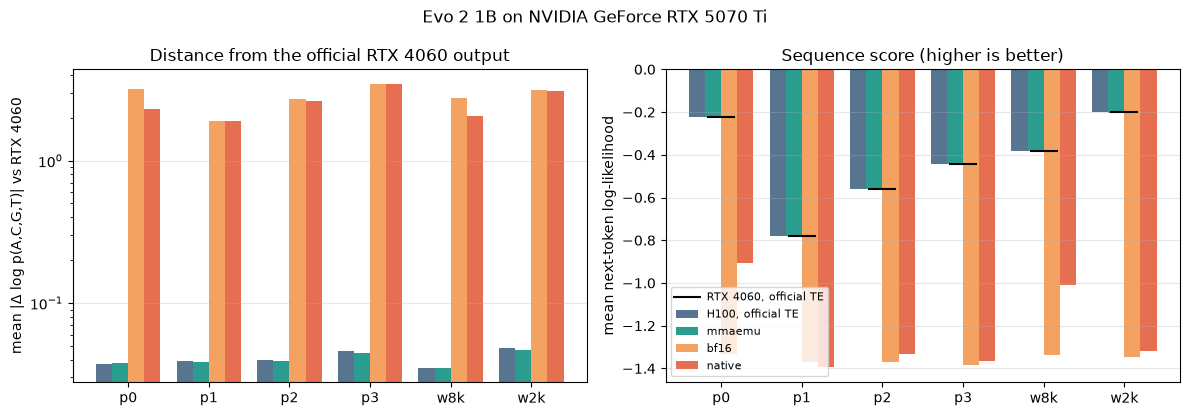

In [9]:
colors = {"mmaemu": "#2a9d8f", "native": "#e76f51", "bf16": "#f4a261", "H100, official TE": "#577590"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
x = np.arange(len(WINDOWS))
order = ["H100, official TE", "mmaemu", "bf16", "native"]
for k, mode in enumerate(order):
    v = win[win["mode"] == mode].set_index("window").loc[WINDOWS]
    axes[0].bar(x + (k - 1.5) * 0.2, v.mean_abs_dlogp_acgt, 0.2, label=mode, color=colors[mode])
    axes[1].bar(x + (k - 1.5) * 0.2, v.mean_next_logprob, 0.2, label=mode, color=colors[mode])
axes[1].scatter(x, [ref["windows"][w]["mean_next_logprob"] for w in WINDOWS], color="black", marker="_", s=400,
                zorder=3, label="RTX 4060, official TE")
axes[0].set_yscale("log")
axes[0].set_ylabel("mean |Δ log p(A,C,G,T)| vs RTX 4060")
axes[1].set_ylabel("mean next-token log-likelihood")
for ax in axes:
    ax.set_xticks(x, WINDOWS)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_title("Distance from the official RTX 4060 output")
axes[1].set_title("Sequence score (higher is better)")
axes[1].legend(fontsize=8, loc="lower left")
fig.suptitle(f"Evo 2 1B on {props.name}")
fig.tight_layout()
plt.show()

## 3. Zero-shot BRCA1 variant effect prediction

The task of the upstream [BRCA1 notebook](https://github.com/ArcInstitute/evo2/tree/main/notebooks/brca1): score
the reference and the variant 8,192-bp window around each single-nucleotide variant measured by saturation genome
editing (Findlay et al. 2018), and use the score difference to separate loss-of-function variants from the rest.
To keep the run short we use the same random subset of 500 variants (seed 0) that was scored with the official
path on the RTX 4060 (AUROC 0.7378) and on the H100 (0.7332). The data files are downloaded from the upstream
repository.

On the RTX 5070 Ti one pass over the 935 windows takes about 15 minutes with mmaemu and 7 minutes natively; set
`N_VARIANTS` lower for a quicker run (the reference AUROC is then recomputed on the same smaller subset).

In [10]:
N_VARIANTS = int(os.environ.get("EVO2_BLACKWELL_VARIANTS", 500))
WINDOW = 8192
URL = "https://raw.githubusercontent.com/ArcInstitute/evo2/main/notebooks/brca1/"
files = {}
for name in ("41586_2018_461_MOESM3_ESM.xlsx", "GRCh37.p13_chr17.fna.gz"):
    files[name] = OUT / name
    if not files[name].exists():
        urllib.request.urlretrieve(URL + name, files[name])

df = pd.read_excel(files["41586_2018_461_MOESM3_ESM.xlsx"], header=2)
df = df[["chromosome", "position (hg19)", "reference", "alt", "function.score.mean", "func.class"]]
df.columns = ["chrom", "pos", "ref", "alt", "score", "class"]
df["class"] = df["class"].replace(["FUNC", "INT"], "FUNC/INT")
print(f"{len(df)} variants, {(df['class'] == 'LOF').sum()} loss of function")
df = df.sample(n=500, random_state=0).reset_index(drop=True).iloc[:N_VARIANTS]
assert (df.pos.values == A["brca1/pos"][:N_VARIANTS]).all() and (df.alt.values == A["brca1/alt"][:N_VARIANTS]).all()

from Bio import SeqIO

with gzip.open(files["GRCh37.p13_chr17.fna.gz"], "rt") as handle:
    chr17 = str(next(SeqIO.parse(handle, "fasta")).seq)


def windows(pos, ref, alt):
    p = pos - 1
    start, end = max(0, p - WINDOW // 2), min(len(chr17), p + WINDOW // 2)
    r = chr17[start:end]
    k = min(WINDOW // 2, p)
    v = r[:k] + alt + r[k + 1:]
    assert r[k] == ref
    return r, v


ref_seqs, ref_of, var_seqs, ref_index = [], {}, [], []
for row in df.itertuples():
    r, v = windows(row.pos, row.ref, row.alt)
    ref_of.setdefault(r, len(ref_seqs))
    if ref_of[r] == len(ref_seqs):
        ref_seqs.append(r)
    ref_index.append(ref_of[r])
    var_seqs.append(v)
ref_index = np.array(ref_index)
lof = (df["class"] == "LOF").values
print(f"subset: {len(df)} variants ({lof.sum()} LOF), {len(ref_seqs)} unique reference windows")

3893 variants, 823 loss of function


subset: 500 variants (111 LOF), 435 unique reference windows


In [11]:
# the RTX 4060 (official TE) scores of the same windows; a prefix of the variants uses a prefix of the windows
ada_rs, ada_vs = A["brca1/rs"][:len(ref_seqs)], A["brca1/vs"][:N_VARIANTS]
ada_delta = ada_vs - ada_rs[ref_index]

brca, scores = [dict(mode="RTX 4060, official TE", auroc=roc_auc_score(lof, -ada_delta))], {}
for mode in MODES:
    set_fp8_mode(evo, scales, mode)
    t = time.perf_counter()
    with torch.inference_mode():
        rs = np.array(evo.score_sequences(ref_seqs))
        vs = np.array(evo.score_sequences(var_seqs))
    seconds = time.perf_counter() - t
    delta = vs - rs[ref_index]
    scores[mode] = dict(rs=rs, vs=vs, delta=delta)
    np.savez(OUT / f"brca1_{mode}.npz", rs=rs, vs=vs, ref_index=ref_index)
    brca.append(dict(mode=mode, auroc=roc_auc_score(lof, -delta), minutes=seconds / 60,
                     delta_pearson_vs_rtx4060=pearsonr(delta, ada_delta)[0],
                     delta_spearman_vs_rtx4060=spearmanr(delta, ada_delta)[0],
                     max_abs_score_diff=float(np.abs(np.r_[rs, vs] - np.r_[ada_rs, ada_vs]).max())))
    print(f"{mode}: AUROC {brca[-1]['auroc']:.4f} in {seconds / 60:.1f} min")
if N_VARIANTS == 500:
    brca.insert(1, dict(mode="H100, official TE", auroc=ref["h100_official_te"]["brca1_auroc"]))
pd.DataFrame(brca).set_index("mode")

mmaemu: AUROC 0.7323 in 15.9 min


native: AUROC 0.5586 in 7.0 min


bf16: AUROC 0.4842 in 7.2 min


,auroc,minutes,delta_pearson_vs_rtx4060,delta_spearman_vs_rtx4060,max_abs_score_diff
mode,,,,,
"RTX 4060, official TE",0.7378,NaN,NaN,NaN,NaN
"H100, official TE",0.7332,NaN,NaN,NaN,NaN
mmaemu,0.7323,15.8959,0.9864,0.9123,0.0004
native,0.5586,6.9962,0.0593,0.1653,0.1801
bf16,0.4842,7.2047,0.0691,0.0784,0.6205


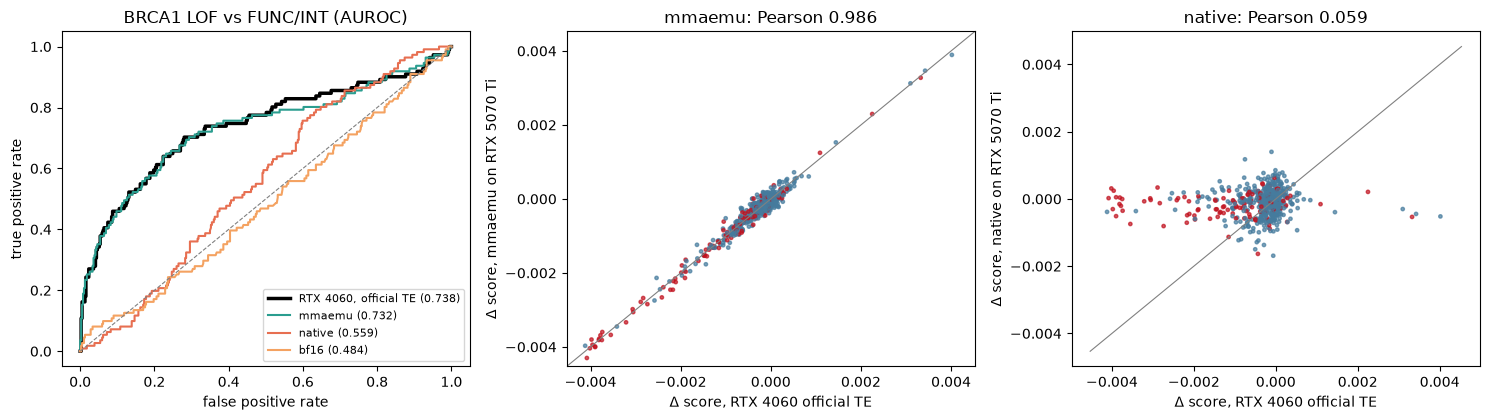

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
fpr, tpr, _ = roc_curve(lof, -ada_delta)
axes[0].plot(fpr, tpr, color="black", lw=2.5, label=f"RTX 4060, official TE ({roc_auc_score(lof, -ada_delta):.3f})")
for mode in MODES:
    fpr, tpr, _ = roc_curve(lof, -scores[mode]["delta"])
    axes[0].plot(fpr, tpr, color=colors[mode], lw=1.5, label=f"{mode} ({roc_auc_score(lof, -scores[mode]['delta']):.3f})")
axes[0].plot([0, 1], [0, 1], color="grey", lw=0.8, ls="--")
axes[0].set_xlabel("false positive rate")
axes[0].set_ylabel("true positive rate")
axes[0].set_title("BRCA1 LOF vs FUNC/INT (AUROC)")
axes[0].legend(fontsize=8, loc="lower right")
lim = np.abs(ada_delta).max() * 1.1
for ax, mode in zip(axes[1:], ("mmaemu", "native")):
    ax.scatter(ada_delta, scores[mode]["delta"], s=6, c=np.where(lof, "#c1121f", "#457b9d"), alpha=0.7)
    ax.plot([-lim, lim], [-lim, lim], color="grey", lw=0.8)
    ax.set_xlabel("Δ score, RTX 4060 official TE")
    ax.set_ylabel(f"Δ score, {mode} on {props.name.replace('NVIDIA GeForce ', '')}")
    ax.set_title(f"{mode}: Pearson {pearsonr(scores[mode]['delta'], ada_delta)[0]:.3f}")
    if mode == "mmaemu":
        ax.set_xlim(-lim, lim)
        ax.set_ylim(-lim, lim)
fig.tight_layout()
plt.show()

In [13]:
# every number above, in one file (OUT/results.json)
from importlib.metadata import version


def records(df):
    return json.loads((df.reset_index() if df.index.name else df).to_json(orient="records"))   # NaN -> null


results = dict(
    gpu=dict(name=props.name, capability=f"{props.major}.{props.minor}", sms=props.multi_processor_count,
             memory_gib=round(props.total_memory / 2**30, 1)),
    versions={name: version(name) for name in ("torch", "mmaemu", "evo2", "vtx", "flash-attn", "numpy")},
    cuda=torch.version.cuda,
    projection0_w2k=dict(table=records(gemm), native_vs_rtx4060=gemm_native),
    windows=records(win), upstream_test=records(test), summary=records(summary),
    brca1=dict(n_variants=N_VARIANTS, n_lof=int(lof.sum()), n_reference_windows=len(ref_seqs),
               table=records(pd.DataFrame(brca).set_index("mode"))))
(OUT / "results.json").write_text(json.dumps(results, indent=1) + "\n")
print("wrote results.json")

wrote results.json


## Summary

Measured on the RTX 5070 Ti (the stored outputs above):

- **One GEMM:** with mmaemu the first FP8 projection's output equals the RTX 4060's bit for bit; natively 70.3% of
  its 11.8 million outputs differ.
- **Upstream test:** loss 0.503 with mmaemu (the test expects 0.502); 1.248 natively and 1.365 with bf16
  projections, the two values reported in evo2 issue #157.
- **Whole model:** with mmaemu the mean |Δ log p(A,C,G,T)| against the RTX 4060 is 0.040, the same size as that of
  the official path on an H100 (0.041). Native FP8 (2.58) and bf16 projections (2.85) are about 65 and 70 times
  further away and lower the score of every window.
- **BRCA1 (500 variants):** AUROC 0.732 with mmaemu, against 0.738 on the RTX 4060 and 0.733 on the H100; the
  per-variant score changes correlate with the RTX 4060's almost as closely as the H100's do (Pearson 0.986 and 0.987).
  The AUROC drops to 0.559 natively and to 0.484 with bf16 projections, whose score changes are almost
  uncorrelated with the RTX 4060's (Pearson 0.06 and 0.07).

Caveats: the full-model logits are not bit-identical to the RTX 4060's, because the non-FP8 operations run natively
on this GPU; mmaemu emulates the RTX 4060's FP8 GEMM and does not model sm_120's own FP8 arithmetic; only the 1B
model is shown. See the [mmaemu README](https://github.com/astding/mmaemu) for the validation behind each kernel and
for the limitations.